In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re


# <p style="font-size: 40px;background-color:#163A5F; color:white; padding:10px 20px; width:95%; border-radius:15px; text-align:center;margin: 0 auto;font-weight: bold;">About Data </p>

## 1. Data Source

The dataset was collected from **Scopus**. Scopus provides bibliographic information about research publications, including titles, abstracts, and subject-area classifications.

The data was collected by conducting relevant searches in Scopus for the three target classes: Science, Business, and Social Science. The search results were exported as CSV files and subsequently combined into a single dataset for the machine learning task.

## 2. Definition of Classes

The project involves three target classes: **Science, Business, and Social Science**. These classes were operationally defined using relevant Scopus subject areas.

- **Science:** This class includes research papers collected from six subject areas: Computer Science, Physics and Astronomy, Chemistry, Biochemistry, Genetics and Molecular Biology, Materials Science, and Earth and Planetary Sciences. These areas were selected to represent a range of scientific and technical disciplines.

- **Business:** This class includes research papers collected using relevant Scopus searches for the Business, Management and Accounting subject area.

- **Social Science:** This class includes research papers collected using relevant Scopus searches for the Social Sciences subject area.

## 3. Number of Papers Collected

A total of **15,000 research paper records** were initially collected across the three target classes.

- **Science:** 5,000 records
- **Business:** 5,000 records
- **Social Science:** 5,000 records

However, the initial records are subject to data-quality checks, including the identification of missing or placeholder abstracts and duplicate papers. The final number of usable records may therefore differ from the initial total after preprocessing and data cleaning.

## 4. Features of the Collected Dataset

| Feature | Description |
|---|---|
| Title | Title of the research paper |
| Abstract | Abstract text used as the primary input for text classification |
| Label | Target class: Science, Business, or Social Science |

# <p style="font-size: 40px;background-color:#163A5F; color:white; padding:10px 20px; width:95%; border-radius:15px; text-align:center;margin: 0 auto;font-weight: bold;"> Exploratory Data Analysis </p>

In [77]:
df = pd.read_csv('train_data_1.csv')

In [78]:
df.head()

,Source title,Abstract,label
0,Pattern Recognition,Large language models (LLMs) offer new opportu...,Science
1,Pattern Recognition,Multi-view clustering has attracted considerab...,Science
2,Robotics and Computer-Integrated Manufacturing,Industrial robots are widely used in intellige...,Science
3,Applied Mathematics and Computation,This study investigates the evolution of coope...,Science
4,Computers and Geotechnics,This study evaluated the hygrothermal desiccat...,Science


In [79]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (15000, 3)

Column names:
['Source title', 'Abstract', 'label']


In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Source title  15000 non-null  str  
 1   Abstract      15000 non-null  str  
 2   label         15000 non-null  str  
dtypes: str(3)
memory usage: 23.1 MB


In [81]:
df.describe()

,Source title,Abstract,label
count,15000,15000,15000
unique,627,13529,3
top,Humanities and Social Sciences Communications,[No abstract available],Science
freq,899,378,5000


### Removing rows which has no abstract available

In [82]:
df[df['Abstract'] == '[No abstract available]'].shape

(378, 3)

In [83]:
df = df[df['Abstract'] != '[No abstract available]'].reset_index(drop=True)
df.shape

(14622, 3)

### Removing duplicate rows with same abstracts

In [84]:
print(df['Abstract'].duplicated().sum())

1094


In [85]:
df = df.drop_duplicates(subset = ['Abstract'], keep = 'first').reset_index(drop = True)
print(df['Abstract'].duplicated().sum())

0


In [86]:
df.shape

(13528, 3)

In [87]:
# Calculate the length of each abstract
df['abstract_length'] = df['Abstract'].str.split().str.len()
df.groupby('label')['abstract_length'].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Business,4455.0,214.785185,62.220561,40.0,170.0,211.0,250.0,831.0
Science,4593.0,210.787938,69.605570,18.0,175.0,213.0,250.0,2313.0
Social Science,4480.0,213.031027,64.934430,15.0,171.0,213.0,250.0,1178.0


label
Science           4593
Social Science    4480
Business          4455
Name: count, dtype: int64


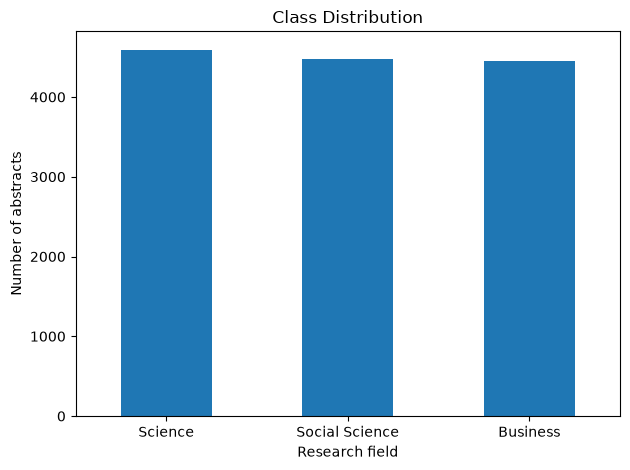

In [88]:
class_counts = df["label"].value_counts()

print(class_counts)

class_counts.plot(
    kind="bar",
    xlabel="Research field",
    ylabel="Number of abstracts",
    title="Class Distribution"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Insights
After data cleaning there is slight imbalance in classes.

# <p style="font-size: 40px;background-color:#163A5F; color:white; padding:10px 20px; width:95%; border-radius:15px; text-align:center;margin: 0 auto;font-weight: bold;">Abstract Cleaning </p>

- **Lowercasing:** Converting all text to lowercase to maintain consistency across the dataset.
- **Removing Punctuation and Special Characters:** Eliminating any unnecessary punctuation marks or special symbols (such as `!`, `#`, `@`) that don't contribute meaningfully to the analysis.
- **Whitespace Removal:** Getting rid of extra spaces or any redundant whitespace between words to ensure clean, properly formatted text.

In [89]:
df['cleaned_abstract'] = (
    df['Abstract']
      .str.lower()
      .str.replace(r'[^\w\s]', ' ', regex=True)
      .str.replace('_', ' ', regex=False)
      .str.replace(r'\s+', ' ', regex=True)
      .str.strip()
)
df[['Abstract', 'cleaned_abstract']].head()

,Abstract,cleaned_abstract
0,Large language models (LLMs) offer new opportu...,large language models llms offer new opportuni...
1,Multi-view clustering has attracted considerab...,multi view clustering has attracted considerab...
2,Industrial robots are widely used in intellige...,industrial robots are widely used in intellige...
3,This study investigates the evolution of coope...,this study investigates the evolution of coope...
4,This study evaluated the hygrothermal desiccat...,this study evaluated the hygrothermal desiccat...


In [90]:
print('Before:', df.loc[2, 'Abstract'])
print('After: ', df.loc[2, 'cleaned_abstract'])


Before: Industrial robots are widely used in intelligent manufacturing due to their high efficiency, flexibility, and repeatability. However, long-term operation under complex working conditions inevitably leads to performance degradation and various faults across mechanical, transmission, and electrical subsystems. Owing to the structural complexity of industrial robots, strong coupling among subsystems, and heterogeneous monitoring data, fault detection and diagnosis has become a challenging yet crucial task for ensuring system reliability and enabling intelligent maintenance. Despite considerable progress, existing studies remain fragmented across different robot subsystems, data modalities, and diagnostic paradigms, and a systematic review dedicated to industrial robot fault detection and diagnosis is still lacking. To address this gap, this paper presents a comprehensive and structured review from three complementary perspectives: fault characteristics and data resources, diagnost

### Define features and target

In [91]:
X = df['cleaned_abstract']
y = df['label']

### Split into training and testing sets

In [92]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify = y)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 10822
Testing samples: 2706

Training class distribution:
label
Science           3674
Social Science    3584
Business          3564
Name: count, dtype: int64

Testing class distribution:
label
Science           919
Social Science    896
Business          891
Name: count, dtype: int64


### Convert abstracts into TF-IDF features

In [93]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9,
    sublinear_tf=True,
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Training TF-IDF shape: (10822, 171440)
Testing TF-IDF shape: (2706, 171440)
Vocabulary size: 171440


### Importing common libraries and Cross Validation Strategy for all the models

In [94]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV


from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [95]:
results = [] #for storing results of different models
best_models = {} #for storing the best model for each algorithm
predictions = {} #for storing the predictions of the best model for each algorithm

# <p style="font-size: 40px;background-color:#163A5F; color:white; padding:10px 20px; width:95%; border-radius:15px; text-align:center;margin: 0 auto;font-weight: bold;">Logistic Regression </p>

In [96]:
from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(max_iter=2000, random_state=42)

# Define values of C to test
param_grid = {"C": [0.1, 10, 25, 50]}

# Perform hyperparameter tuning using 5-fold cross-validation
grid_search = GridSearchCV(
    estimator = lr_model,
    param_grid = param_grid,
    cv = cv, 
    scoring = "f1_macro",
    n_jobs = -1
)

# Train the model
grid_search.fit(X_train_tfidf, y_train)

# Get the best model and hyperparameter
lr_model = grid_search.best_estimator_

print("Best C:", grid_search.best_params_["C"])
print("Best CV Macro F1:", grid_search.best_score_)

# Prediction using the tuned model
y_pred = lr_model.predict(X_test_tfidf)

#Calculate evaluation metrics
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (Macro)": precision_score(y_test, y_pred, average="macro"),
    "Recall (Macro)": recall_score(y_test, y_pred, average="macro"),
    "F1 (Macro)": f1_score(y_test, y_pred, average="macro")
}

results.append(lr_results)

best_models["Logistic Regression"] = lr_model
predictions["Logistic Regression"] = y_pred

pd.DataFrame(results).round(3)


Best C: 25
Best CV Macro F1: 0.8370593619098925


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,Logistic Regression,0.84,0.838,0.839,0.838


### Confusion Matrix for Logistic Regression

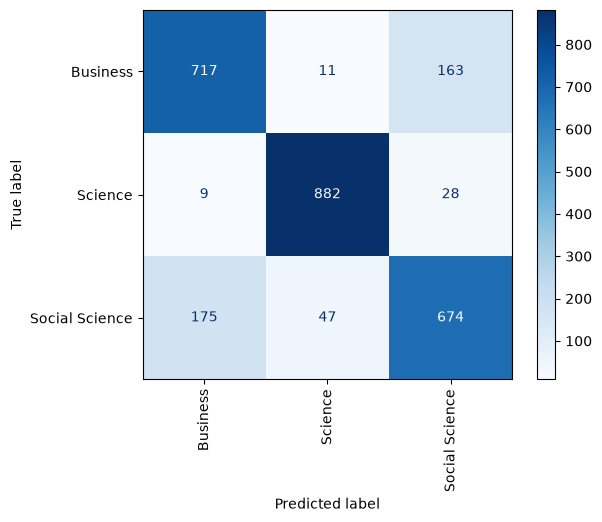

In [97]:
cm = confusion_matrix(y_test, y_pred, labels=lr_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=lr_model.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.show()

# <p style="font-size: 40px;background-color:#163A5F; color:white; padding:10px 20px; width:95%; border-radius:15px; text-align:center;margin: 0 auto;font-weight: bold;">SVM </p>

In [98]:
from sklearn.svm import LinearSVC

#create the model
svm_model = LinearSVC(max_iter=2000, random_state=42)

#define values of C to test
param_grid = {"C": [0.1, 10, 25, 50]}   

#perform hyperparameter tuning using 5-fold cross-validation
grid_search = GridSearchCV(
    estimator = svm_model,
    param_grid = param_grid,
    cv = cv,
    scoring = "f1_macro",
    n_jobs = -1
)   

#train the model
grid_search.fit(X_train_tfidf, y_train)

#get the best model and hyperparameter
svm_model = grid_search.best_estimator_ 

print("Best C:", grid_search.best_params_["C"])
print("Best CV Macro F1:", grid_search.best_score_)

#prediction using the tuned model
y_pred = svm_model.predict(X_test_tfidf)

#calculate evaluation metrics
svm_results = {
    "Model": "SVM",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (Macro)": precision_score(y_test, y_pred, average="macro"),
    "Recall (Macro)": recall_score(y_test, y_pred, average="macro"),
    "F1 (Macro)": f1_score(y_test, y_pred, average="macro")
}   

results.append(svm_results)

best_models["SVM"] = svm_model
predictions["SVM"] = y_pred

pd.DataFrame(results).round(3)

Best C: 10
Best CV Macro F1: 0.8341138241242076


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,Logistic Regression,0.840,0.838,0.839,0.838
1,SVM,0.839,0.836,0.837,0.836


### Confusion Matrix for SVM

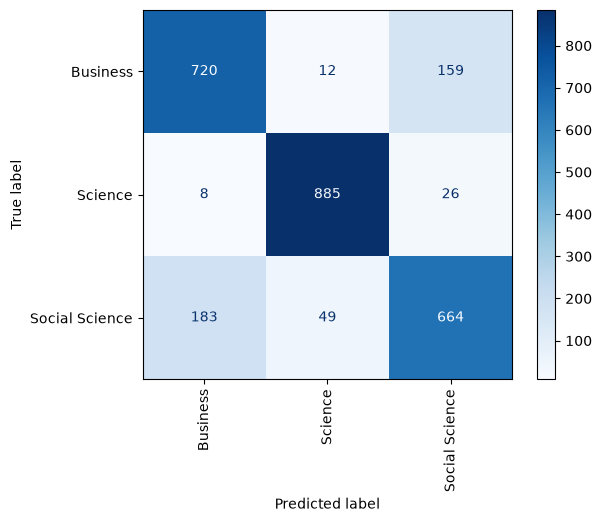

In [99]:
cm = confusion_matrix(y_test, y_pred, labels=svm_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=svm_model.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.show()

# <p style="font-size: 40px;background-color:#163A5F; color:white; padding:10px 20px; width:95%; border-radius:15px; text-align:center;margin: 0 auto;font-weight: bold;">Naive Bayes </p>

We implemented three Naive Bayes classifiers: 
1. Multinomial Naive Bayes
2. Complement Naive Bayes
3. Bernoulli Naive Bayes

- We trained MultinomialNB and ComplementNB using TF-IDF features. 
- BernoulliNB was trained separately using binary word-presence features, as it focuses on whether words occur rather than their TF-IDF weights. 

### Multinomial Naive Bayes and Complement Naive Bayes

In [100]:
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB

nb_results = [] #for storing results of different models
nb_best_models={}#for storing the best model for each algorithm
nb_predictions = {} #for storing the predictions of the best model for each algorithm

nb_models = {'MultinomialNB': MultinomialNB(), 'ComplementNB': ComplementNB()}
#create the model
for name, model in nb_models.items():
    nb_model = model

    #define values of alpha to test
    param_grid = {"alpha": [0.01, 0.1, 0.5, 1, 2, 5, 10]}

    #perform hyperparameter tuning using 5-fold cross-validation
    grid_search = GridSearchCV(
        estimator = nb_model,
        param_grid = param_grid,
        cv = cv,
        scoring = "f1_macro",
        n_jobs = -1
    )

    #train the model
    grid_search.fit(X_train_tfidf, y_train)

    #get the best model and hyperparameter
    nb_model = grid_search.best_estimator_

    print("Best alpha:", grid_search.best_params_["alpha"])
    print("Best CV Macro F1:", grid_search.best_score_)

    #prediction using the tuned model
    y_pred = nb_model.predict(X_test_tfidf)

    #calculate evaluation metrics
    model_results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (Macro)": recall_score(y_test, y_pred, average="macro"),
        "F1 (Macro)": f1_score(y_test, y_pred, average="macro")
    }

    nb_results.append(model_results)
    nb_best_models[name] = nb_model
    nb_predictions[name] = y_pred

pd.DataFrame(nb_results).round(3)

Best alpha: 0.01
Best CV Macro F1: 0.8197853220600543
Best alpha: 0.1
Best CV Macro F1: 0.8082323555962285


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,MultinomialNB,0.829,0.826,0.827,0.826
1,ComplementNB,0.819,0.818,0.817,0.812


### Bernoulli Naive Bayes

In [101]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import BernoulliNB

# Convert text into binary word-presence features
binary_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9,
    binary=True
)

X_train_binary = binary_vectorizer.fit_transform(X_train)
X_test_binary = binary_vectorizer.transform(X_test)

# Create the model
nb_model = BernoulliNB()

# Define values of alpha to test
param_grid = {"alpha": [0.01, 0.1, 0.5, 1, 2, 5, 10]}

# Hyperparameter tuning
grid_search = GridSearchCV(
    estimator=nb_model,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

# Train the model
grid_search.fit(X_train_binary, y_train)

# Get the best model and hyperparameter
nb_model = grid_search.best_estimator_

print("Best alpha:", grid_search.best_params_["alpha"])
print("Best CV Macro F1:", grid_search.best_score_)

# Prediction
y_pred = nb_model.predict(X_test_binary)

# Evaluation metrics
bernoulli_results = {
    "Model": "BernoulliNB",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (Macro)": precision_score(y_test, y_pred, average="macro"),
    "Recall (Macro)": recall_score(y_test, y_pred, average="macro"),
    "F1 (Macro)": f1_score(y_test, y_pred, average="macro")
}

nb_results.append(bernoulli_results)
    
nb_best_models["BernoulliNB"] = nb_model
nb_predictions["BernoulliNB"] = y_pred

pd.DataFrame(nb_results).round(3)

Best alpha: 0.5
Best CV Macro F1: 0.8165469409351495


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,MultinomialNB,0.829,0.826,0.827,0.826
1,ComplementNB,0.819,0.818,0.817,0.812
2,BernoulliNB,0.819,0.817,0.817,0.816


### Results and Comparison

- All three Naive Bayes classifiers achieved similar performance, with accuracy around 82.6–81.2%. MultinomialNB  performed marginally better than ComplementNB and BernoulliNB, achieving the highest macro-F1 score of 0.826. 

- We will select MultinomialNB as it achieves the joint-highest accuracy,precision and macro-F1.

In [102]:
results.append(nb_results[0])

best_models["MultinomialNB"] = nb_best_models["MultinomialNB"]
predictions["MultinomialNB"] = nb_predictions["MultinomialNB"]

pd.DataFrame(results).round(3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,Logistic Regression,0.840,0.838,0.839,0.838
1,SVM,0.839,0.836,0.837,0.836
2,MultinomialNB,0.829,0.826,0.827,0.826


### Confusion Matrix for Naive Bayes

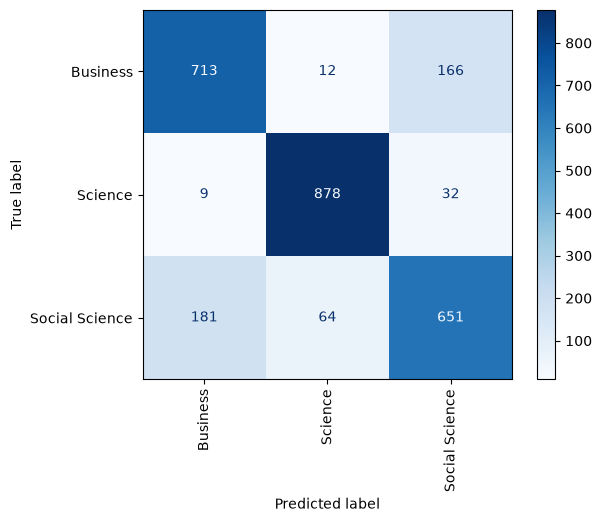

In [103]:
cm = confusion_matrix(y_test, predictions["MultinomialNB"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm , display_labels=["Business", "Science", "Social Science"])
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.show()

# <p style="font-size: 40px;background-color:#163A5F; color:white; padding:10px 20px; width:95%; border-radius:15px; text-align:center;margin: 0 auto;font-weight: bold;">KNN Classification </p>

In [104]:
from sklearn.neighbors import KNeighborsClassifier

#create the model
knn_model = KNeighborsClassifier()

#define values of k to test
param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"],
    "metric": ["cosine", "euclidean"]
}

#perform hyperparameter tuning using 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=knn_model,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

#train the model
grid_search.fit(X_train_tfidf, y_train)

#get the best model and hyperparameters
knn_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best CV Macro F1:", grid_search.best_score_)

#prediction using the tuned model
y_pred = knn_model.predict(X_test_tfidf)

#calculate evaluation metrics
knn_results = {
    "Model": "kNN",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (Macro)": precision_score(y_test, y_pred, average="macro"),
    "Recall (Macro)": recall_score(y_test, y_pred, average="macro"),
    "F1 (Macro)": f1_score(y_test, y_pred, average="macro")
}

results.append(knn_results)

best_models["kNN"] = knn_model
predictions["kNN"] = y_pred

pd.DataFrame(results).round(3)

Best Parameters: {'metric': 'cosine', 'n_neighbors': 9, 'weights': 'distance'}
Best CV Macro F1: 0.8346592818731855


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,Logistic Regression,0.840,0.838,0.839,0.838
1,SVM,0.839,0.836,0.837,0.836
2,MultinomialNB,0.829,0.826,0.827,0.826
3,kNN,0.846,0.844,0.845,0.844


### Confusion Matrix for KNN

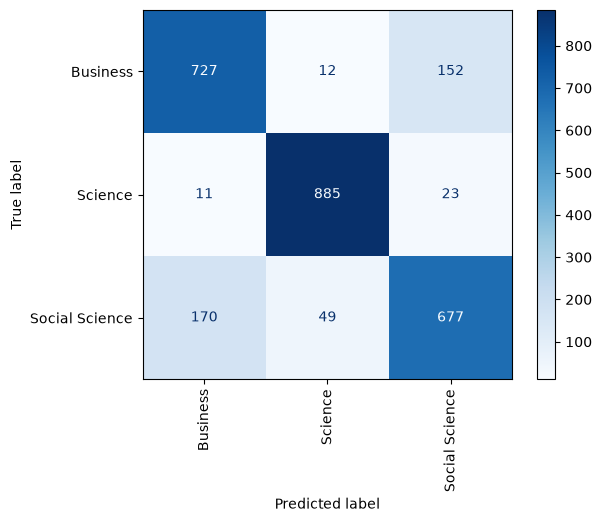

In [105]:
cm = confusion_matrix(y_test, y_pred, labels=knn_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn_model.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.show()

# <p style="font-size: 40px;background-color:#163A5F; color:white; padding:10px 20px; width:95%; border-radius:15px; text-align:center;margin: 0 auto;font-weight: bold;">Decision Tree Classifier </p>

In [106]:
from sklearn.tree import DecisionTreeClassifier

# Create the model
dt_model = DecisionTreeClassifier(random_state=42)

# Define hyperparameters to test
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [1, 5],
    "class_weight": [None, "balanced"]
}

cv1 = StratifiedKFold(n_splits=3,shuffle=True,random_state=42)

# Perform hyperparameter tuning using 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid,
    cv=cv1,
    scoring="f1_macro",
    n_jobs=-1
)

# Train the model
grid_search.fit(X_train_tfidf, y_train)

# Get the best model and hyperparameters
dt_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best CV Macro F1:", grid_search.best_score_)

# Prediction using the tuned model
y_pred = dt_model.predict(X_test_tfidf)

# Calculate evaluation metrics
dt_results = {
    "Model": "Decision Tree",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (Macro)": precision_score(y_test, y_pred, average="macro"),
    "Recall (Macro)": recall_score(y_test, y_pred, average="macro"),
    "F1 (Macro)": f1_score(y_test, y_pred, average="macro")
}

results.append(dt_results)

best_models["Decision Tree"] = dt_model
predictions["Decision Tree"] = y_pred

pd.DataFrame(results).round(3)

/Users/aditya/Sem 1/Prog for DS/.venv/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Parameters: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 30, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV Macro F1: 0.6941198738068217


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,Logistic Regression,0.840,0.838,0.839,0.838
1,SVM,0.839,0.836,0.837,0.836
2,MultinomialNB,0.829,0.826,0.827,0.826
3,kNN,0.846,0.844,0.845,0.844
4,Decision Tree,0.705,0.705,0.705,0.705


### Confusion Matrix for Decision Tree 

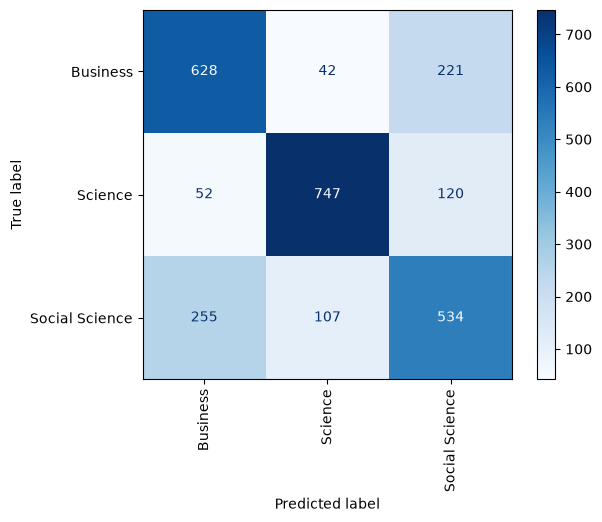

In [107]:
cm = confusion_matrix(y_test, y_pred, labels=dt_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dt_model.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.show()

# <p style="font-size: 40px;background-color:#163A5F; color:white; padding:10px 20px; width:95%; border-radius:15px; text-align:center;margin: 0 auto;font-weight: bold;">Random Forest </p>

In [108]:
from sklearn.ensemble import RandomForestClassifier

#rf_model
rf_model = RandomForestClassifier(random_state = 42)

# Train the model
rf_model.fit(X_train_tfidf, y_train)

# Prediction using the tuned model
y_pred = rf_model.predict(X_test_tfidf)

# Calculate evaluation metrics
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (Macro)": precision_score(y_test, y_pred, average="macro"),
    "Recall (Macro)": recall_score(y_test, y_pred, average="macro"),
    "F1 (Macro)": f1_score(y_test, y_pred, average="macro")
}

results.append(rf_results)

best_models["Random Forest"] = rf_model
predictions["Random Forest"] = y_pred

pd.DataFrame(results).round(3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,Logistic Regression,0.840,0.838,0.839,0.838
1,SVM,0.839,0.836,0.837,0.836
2,MultinomialNB,0.829,0.826,0.827,0.826
3,kNN,0.846,0.844,0.845,0.844
4,Decision Tree,0.705,0.705,0.705,0.705
5,Random Forest,0.826,0.823,0.825,0.822


### Confusion Matrix for Random Forest

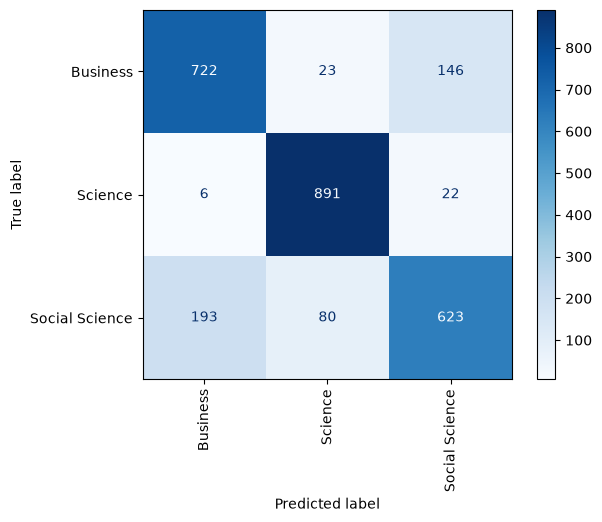

In [75]:
cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf_model.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation='vertical')
plt.show()

# <p style="font-size: 40px;background-color:#163A5F; color:white; padding:10px 20px; width:95%; border-radius:15px; text-align:center;margin: 0 auto;font-weight: bold;"> Results </p>

### Comparison of all the Models and scoring metrics

In [109]:
pd.DataFrame(results).round(3).sort_values(by="F1 (Macro)", ascending=False).reset_index(drop=True)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro)
0,kNN,0.846,0.844,0.845,0.844
1,Logistic Regression,0.840,0.838,0.839,0.838
2,SVM,0.839,0.836,0.837,0.836
3,MultinomialNB,0.829,0.826,0.827,0.826
4,Random Forest,0.826,0.823,0.825,0.822
5,Decision Tree,0.705,0.705,0.705,0.705


**kNN achieved the best overall performance**, with an accuracy of 84.6% and a macro F1-score of 84.4%. Logistic Regression and SVM also performed competitively, achieving accuracies of 84.0% and 83.9%, respectively. Multinomial Naive Bayes achieved an accuracy of 82.9%, followed closely by Random Forest at 82.6%.

Decision Tree showed the lowest performance, with an accuracy of 70.5% and a macro F1-score of 70.5%.

### Number of Miss-classifications

In [110]:
misclassification_results = []

for model_name, y_pred in predictions.items():
    incorrect = (y_test != y_pred).sum()
    total = len(y_test)

    misclassification_results.append({
        "Model": model_name,
        "Misclassified Samples": incorrect,
        "Correctly Classified Samples": total - incorrect,
        "Misclassification Rate %": (incorrect / total) * 100
    })

misclassification_df = pd.DataFrame(misclassification_results).round(2).sort_values(by="Misclassification Rate %", ascending=True).reset_index(drop=True)

display(misclassification_df)

,Model,Misclassified Samples,Correctly Classified Samples,Misclassification Rate %
0,kNN,417,2289,15.41
1,Logistic Regression,433,2273,16.00
2,SVM,437,2269,16.15
3,MultinomialNB,464,2242,17.15
4,Random Forest,470,2236,17.37
5,Decision Tree,797,1909,29.45


### Visualizing the results

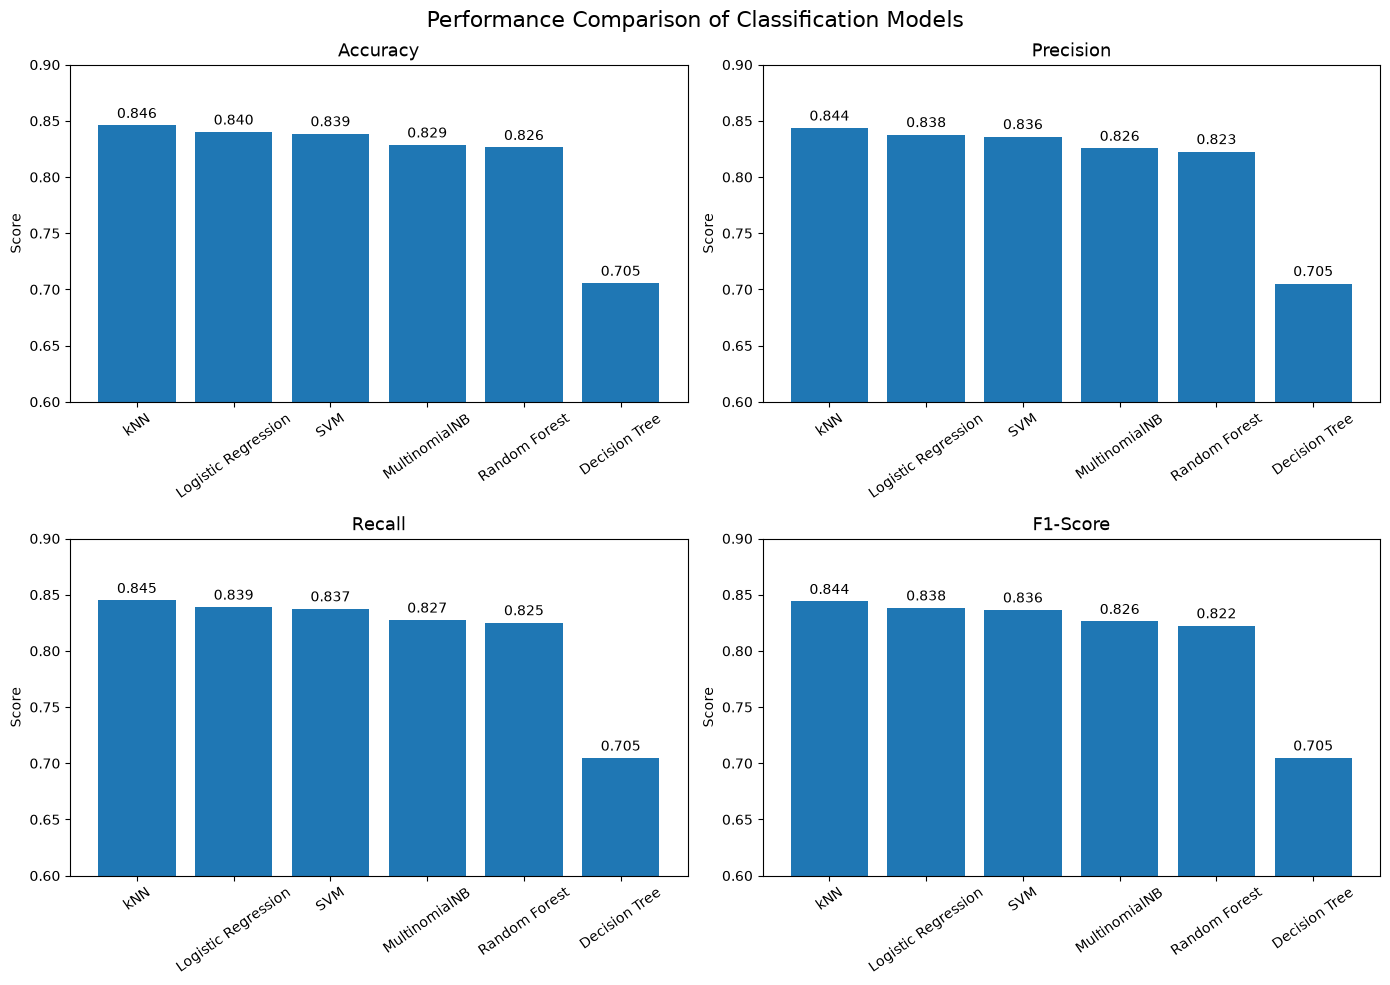

In [111]:
results_df = pd.DataFrame(results).sort_values(by="F1 (Macro)", ascending=False).reset_index(drop=True)

metrics = [
    ("Accuracy", "Accuracy"),
    ("Precision (Macro)", "Precision"),
    ("Recall (Macro)", "Recall"),
    ("F1 (Macro)", "F1-Score")
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (column, title) in zip(axes.flat, metrics):
    bars = ax.bar(results_df["Model"],results_df[column])

    ax.set_title(title, fontsize=13)
    ax.set_ylabel("Score")
    ax.set_ylim(0.6, 0.9)
    ax.tick_params(axis="x", rotation=35)

    # Display score above each bar
    ax.bar_label(bars, fmt="%.3f", padding=3)

plt.suptitle("Performance Comparison of Classification Models",fontsize=16)

plt.tight_layout()
plt.show()

### Confusion Matrix

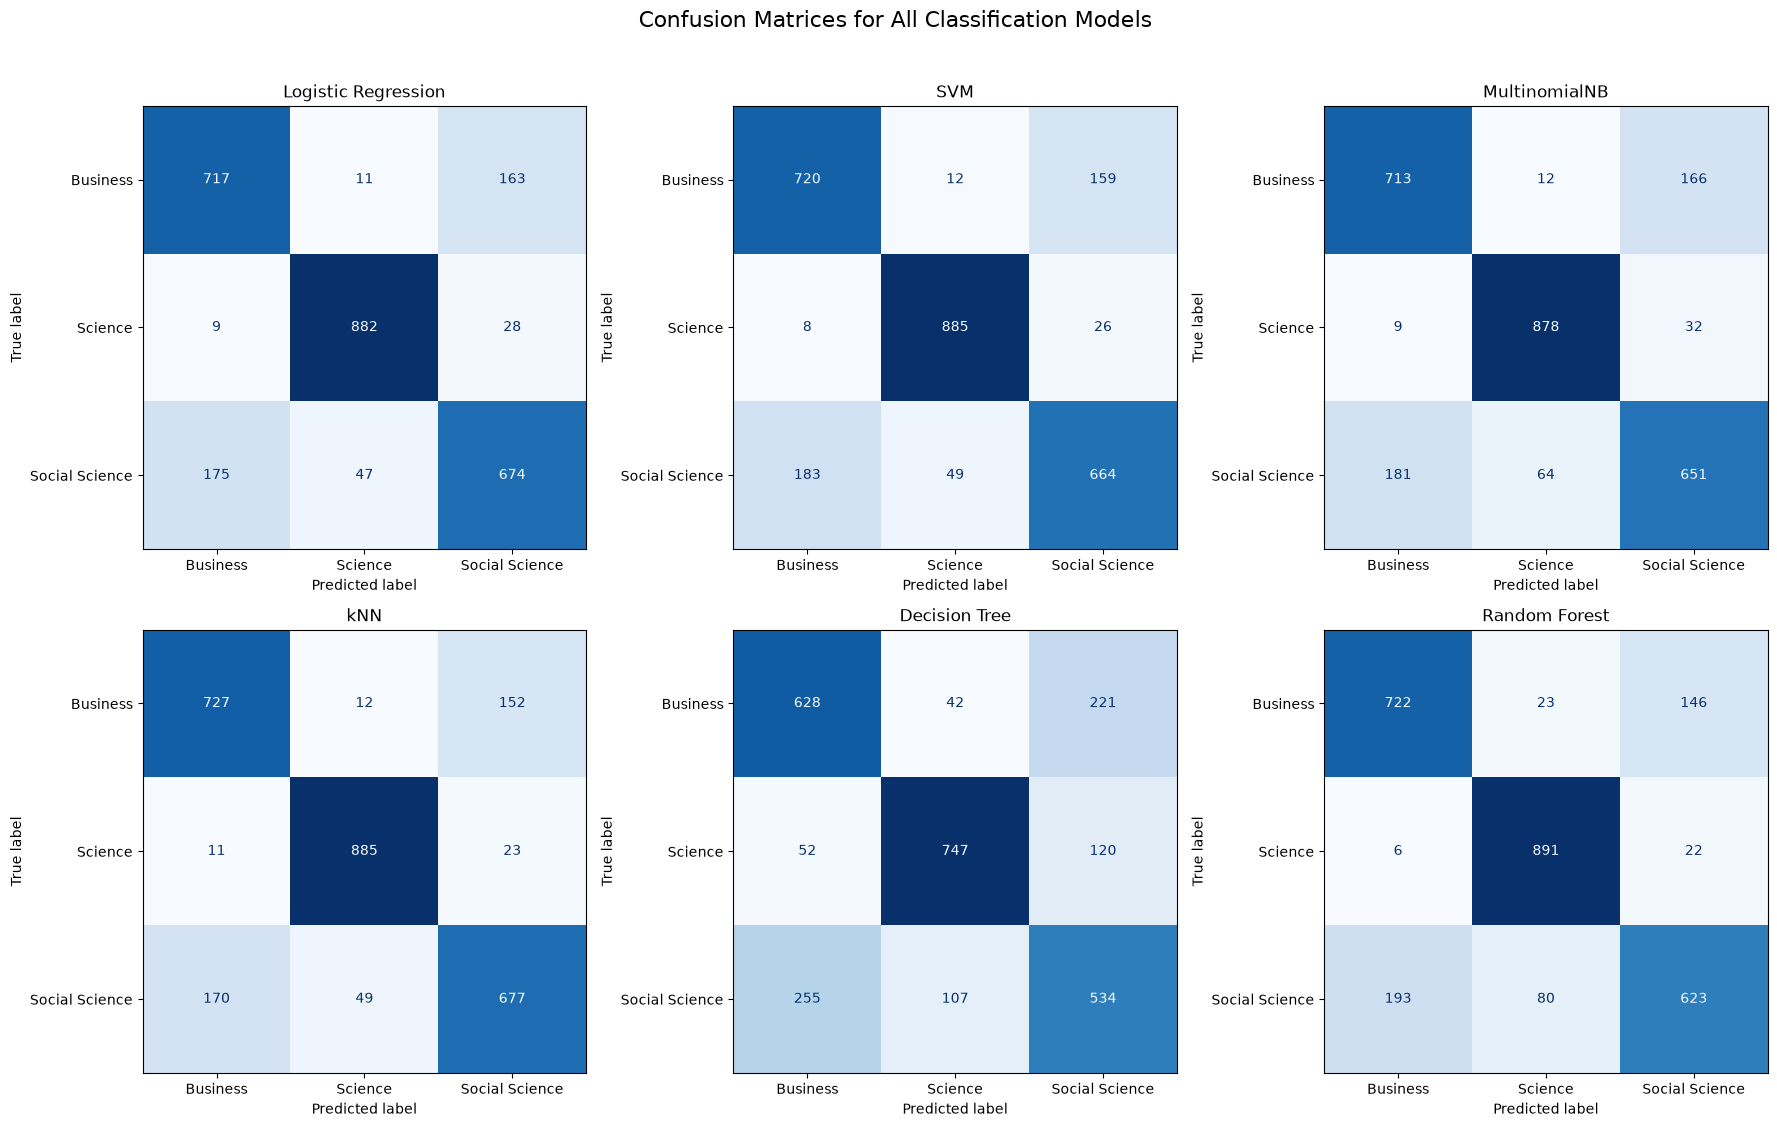

In [112]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, (model_name, y_pred) in zip(axes.flat, predictions.items()):
    
    #calculate confusion matrix for each model
    cm = confusion_matrix(y_test, y_pred, labels=best_models[model_name].classes_)
    
    #display confusion matrix for each model
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_models[model_name].classes_)
    disp.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='horizontal', colorbar=False)

    ax.set_title(model_name, fontsize=12)

plt.suptitle(
    "Confusion Matrices for All Classification Models",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

### Saving the model weights and text preprocessing weights for predicting unseen data

In [113]:
import joblib

joblib.dump(vectorizer, "mt_tfidf_vectorizer.joblib")
joblib.dump(lr_model, "mt_logistic_regression_model.joblib")
joblib.dump(knn_model,"mt_knn_model.joblib")

['mt_knn_model.joblib']

In [119]:
df_test = pd.read_csv("knn1_pred.csv")
df_test.head()

,Source title,Abstract,label,predicted
0,Advances in Applied Mathematics and Mechanics,"In this paper, a three-level linearized finite...",Science,Science
1,Advances in Applied Mathematics and Mechanics,This study proposes a non-classical Timoshenko...,Science,Science
2,Nonlinear Analysis: Real World Applications,We introduce and analyze a static piezoelectri...,Science,Science
3,Advances in Applied Mathematics and Mechanics,"In this paper, the 2D cracked phononic crystal...",Science,Science
4,Inverse Problems and Imaging,We consider a two-component semilinear reactio...,Science,Science


knn

In [115]:
abc = {
    "Accuracy": accuracy_score(df_test['Label'],df_test['predicted']),
    "Precision (Macro)": precision_score(df_test['Label'],df_test['predicted'], average="macro"),
    "Recall (Macro)": recall_score(df_test['Label'],df_test['predicted'], average="macro"),
    "F1 (Macro)": f1_score(df_test['Label'],df_test['predicted'], average="macro")
}
abc

{'Accuracy': 0.703613479496549,
 'Precision (Macro)': 0.7006796804425264,
 'Recall (Macro)': 0.7043490928412718,
 'F1 (Macro)': 0.6974134222287912}

In [121]:
abc = {
    "Accuracy": accuracy_score(df_test['label'],df_test['predicted']),
    "Precision (Macro)": precision_score(df_test['label'],df_test['predicted'], average="macro"),
    "Recall (Macro)": recall_score(df_test['label'],df_test['predicted'], average="macro"),
    "F1 (Macro)": f1_score(df_test['label'],df_test['predicted'], average="macro")
}
abc

{'Accuracy': 0.8333333333333334,
 'Precision (Macro)': 0.8690302735955965,
 'Recall (Macro)': 0.8333333333333334,
 'F1 (Macro)': 0.8256442445165115}

In [122]:
df_test = pd.read_csv("lr1_pred.csv")
df_test.head()

,Source title,Abstract,label,predicted
0,Advances in Applied Mathematics and Mechanics,"In this paper, a three-level linearized finite...",Science,Science
1,Advances in Applied Mathematics and Mechanics,This study proposes a non-classical Timoshenko...,Science,Science
2,Nonlinear Analysis: Real World Applications,We introduce and analyze a static piezoelectri...,Science,Science
3,Advances in Applied Mathematics and Mechanics,"In this paper, the 2D cracked phononic crystal...",Science,Science
4,Inverse Problems and Imaging,We consider a two-component semilinear reactio...,Science,Science


lr

In [ ]:
abc = {
    "Accuracy": accuracy_score(df_test['Label'],df_test['predicted']),
    "Precision (Macro)": precision_score(df_test['Label'],df_test['predicted'], average="macro"),
    "Recall (Macro)": recall_score(df_test['Label'],df_test['predicted'], average="macro"),
    "F1 (Macro)": f1_score(df_test['Label'],df_test['predicted'], average="macro")
}
abc

{'Accuracy': 0.6983353633779943,
 'Precision (Macro)': 0.7095746609810528,
 'Recall (Macro)': 0.7072959935026525,
 'F1 (Macro)': 0.6962452640377176}

In [123]:
abc = {
    "Accuracy": accuracy_score(df_test['label'],df_test['predicted']),
    "Precision (Macro)": precision_score(df_test['label'],df_test['predicted'], average="macro"),
    "Recall (Macro)": recall_score(df_test['label'],df_test['predicted'], average="macro"),
    "F1 (Macro)": f1_score(df_test['label'],df_test['predicted'], average="macro")
}
abc

{'Accuracy': 0.8,
 'Precision (Macro)': 0.8474283717679943,
 'Recall (Macro)': 0.7999999999999999,
 'F1 (Macro)': 0.7883240490211683}